# Part 5: Create an Interactive Plot with Plotly

In [13]:
%pip install plotly nbformat

   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ----- ---------------------------------- 1.3/9.7 MB 10.5 MB/s eta 0:00:01
   ---------------- ----------------------- 3.9/9.7 MB 9.7 MB/s eta 0:00:01
   -------------------- ------------------- 5.0/9.7 MB 8.2 MB/s eta 0:00:01
   --------------------------- ------------ 6.6/9.7 MB 8.1 MB/s eta 0:00:01
   -------------------------------- ------- 7.9/9.7 MB 7.8 MB/s eta 0:00:01
   -------------------------------------- - 9.4/9.7 MB 7.7 MB/s eta 0:00:01
   ---------------------------------------- 9.7/9.7 MB 7.5 MB/s eta 0:00:00

   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ----------------------------------------

t.shape = (100, 1)
s.shape = (100, 3)
t.shape = (100, 1)
s.shape = (100, 3)
phase_shift = 0.25 pi


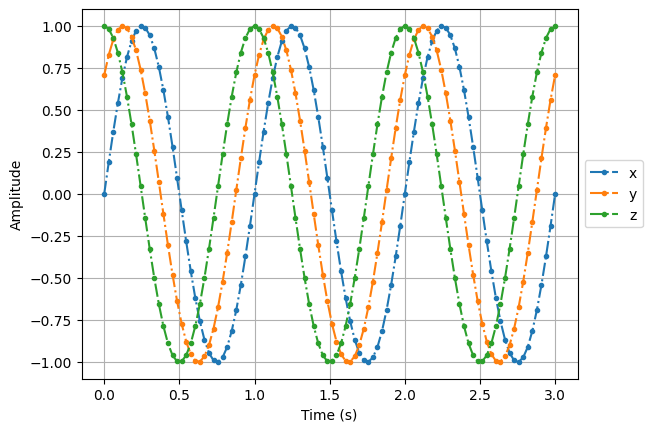

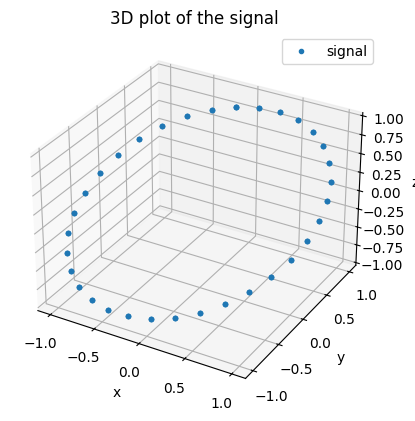

ds_forward.shape = (100, 3)
ds_central.shape = (100, 3)


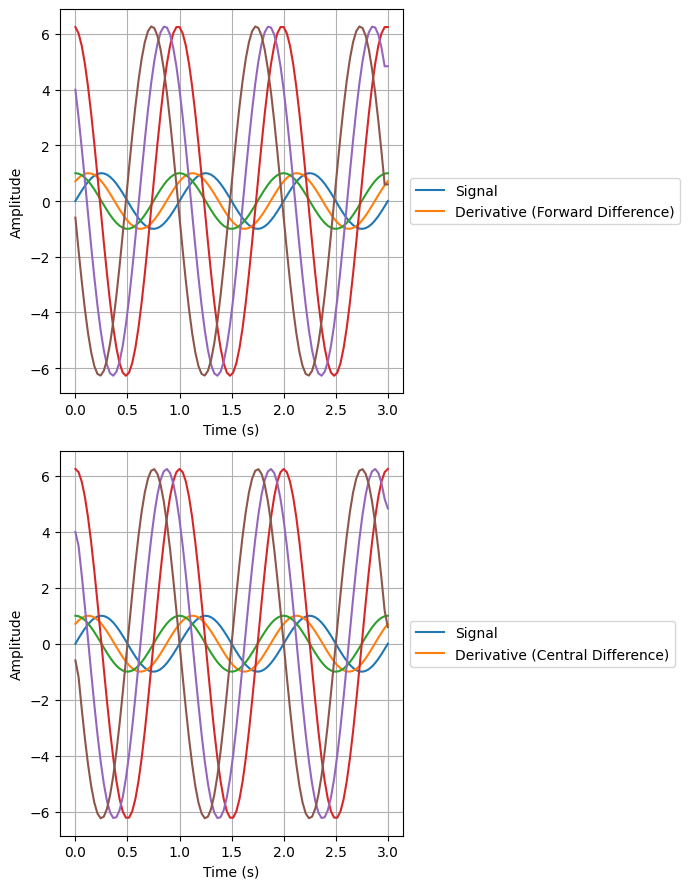

Max error, forward: 0.5974806053596778
Max error, central: 0.0378942432860665
t.shape = (100, 1)
s.shape = (100, 3)
t.shape = (100, 1)
s.shape = (100, 3)
phase_shift = 0.25 pi


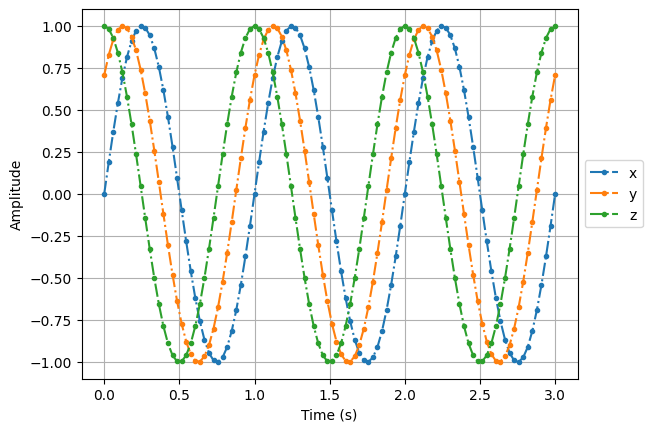

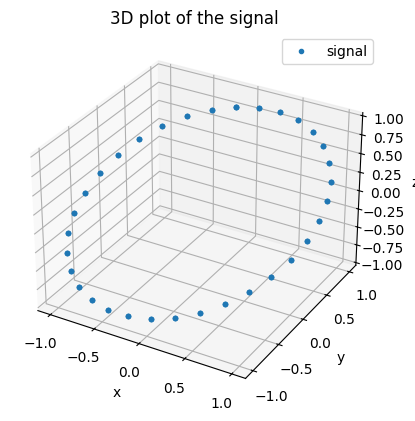

ds_forward.shape = (100, 3)
ds_central.shape = (100, 3)


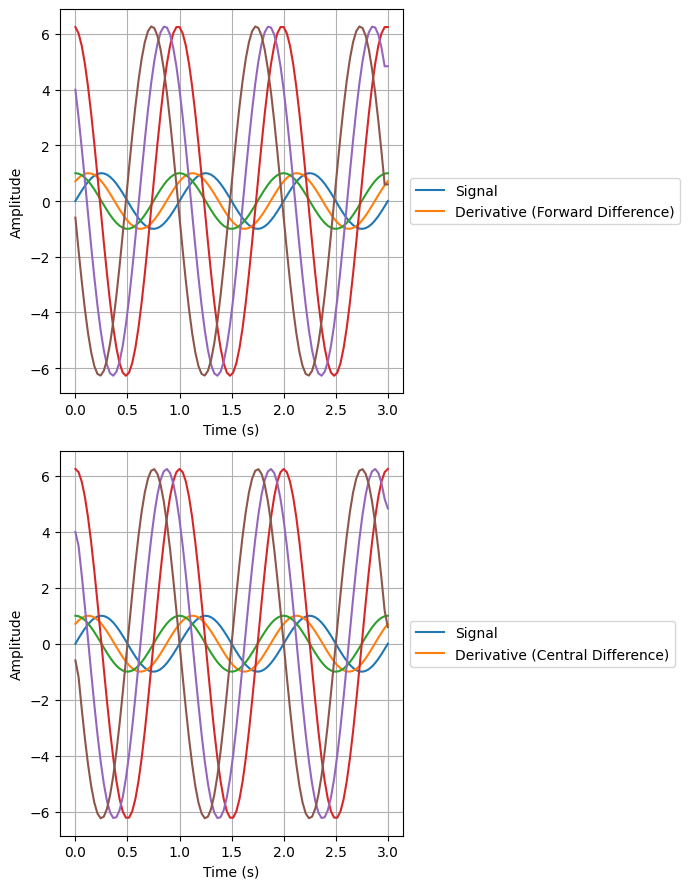

Max error, forward: 0.5974806053596778
Max error, central: 0.0378942432860665
signal_1d.shape = (50, 1)
speed_1d.shape = (50, 1)
speed_1d = [[2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]
 [2.]]
speed_1d_neg = [[3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]
 [3.]]
speed_2d = [[5.]
 [5.]
 [5.]
 [5.]
 [5.]
 [5.]
 [5.]
 [5.]
 [5.]
 [5.]
 [5.]
 [5.]
 [5.]
 [5.]
 [5.]
 [5.]
 [5.]
 [5.]
 [5.]
 [5.]
 [5.]
 [5.]
 [5.]
 [5.]
 [5.]
 [5.]
 [5.]
 [5.]
 [5.]
 [5.]
 [5.]
 [5.]
 [5.]
 [5.]
 [5.]
 [5.]
 [5.]
 [5.]
 [5.

In [14]:
%run section_1.ipynb
%run section_2.ipynb

In [15]:
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots

# Use an interactive Plotly renderer
pio.renderers.default = "notebook_connected"

# Calculate speed using the group's existing function
speed = tangential_speed(s, t)
time = t.flatten()

# Create two plots
fig = make_subplots(
    rows=2,
    cols=1,
    shared_xaxes=True,
    vertical_spacing=0.15,
    subplot_titles=("Signal (x, y, z)", "Tangential Speed")
)


# Plot the three signal components
for i, name in enumerate(["x", "y", "z"]):
    fig.add_trace(
        go.Scatter(
            x=time,
            y=s[:, i],
            mode="lines",
            name=name
        ),
        row=1,
        col=1
    )

# Plot tangential speed
fig.add_trace(
    go.Scatter(
        x=time,
        y=speed.flatten(),
        mode="lines",
        name="Tangential speed"
    ),
    row=2,
    col=1
)

# Axis labels
fig.update_xaxes(title_text="Time (s)", row=2, col=1)
fig.update_yaxes(title_text="Amplitude (a.u.)", row=1, col=1)
fig.update_yaxes(title_text="Speed (a.u./s)", row=2, col=1)

fig.update_layout(
    title="Signal and Tangential Speed",
    height=700,
    hovermode="x unified"
)

fig.show()

In [16]:
print("Number of samples:", len(t))
print("Start time:", t[0, 0])
print("End time:", t[-1, 0])
print("Sampling rate (Hz):", 1 / np.mean(np.diff(t.flatten())))
print("Signal shape:", s.shape)

Number of samples: 100
Start time: 0.0
End time: 3.0
Sampling rate (Hz): 33.0
Signal shape: (100, 3)


### Note on the edge values

The tangential speed is estimated using the central-difference method. At the first and last samples, a one-sided difference is used because a previous or next sample is unavailable. Therefore, the speed estimates at these two points may be less accurate than the estimates for the interior samples.

In [17]:
fig.write_html(
    "part5_interactive_plot.html",
    include_plotlyjs=True
)

print("HTML file created successfully!")

HTML file created successfully!
